In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Generate normal salary data
np.random.seed(42)

normal_salaries = np.random.normal(
    loc=50000,
    scale=8000,
    size=200
)

# Add some outliers
outliers = np.array([
    100000, 110000, 120000, 130000, 140000
])

# Combine normal data and outliers
salary = np.concatenate([
    normal_salaries,
    outliers
])

# Create DataFrame
df = pd.DataFrame({
    'Salary': salary
})

print("Dataset:")
display(df.head(10))

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
display(df.describe())

Dataset:


,Salary
0,53973.713224
1,48893.885591
2,55181.508305
3,62184.238851
4,48126.773002
5,48126.904344
6,62633.702524
7,56139.477833
8,46244.204913
9,54340.480349



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Salary  205 non-null    float64
dtypes: float64(1)
memory usage: 1.7 KB
None

Statistical Summary:


,Salary
count,205.000000
mean,51389.104662
std,13314.607121
min,29042.039167
25%,44559.802227
50%,50465.669748
75%,54694.856750
max,140000.000000


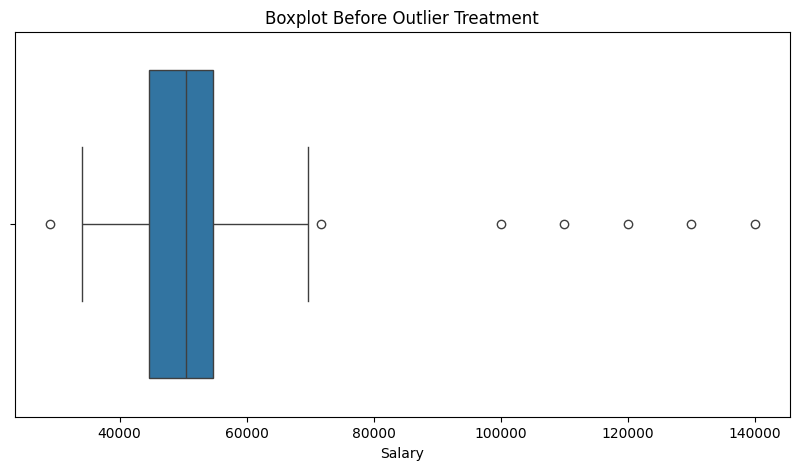

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Salary'])

plt.title("Boxplot Before Outlier Treatment")
plt.xlabel("Salary")

plt.show()

In [ ]:
# Calculate Q1 and Q3
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
iqr_outliers = df[
    (df['Salary'] < lower_bound) |
    (df['Salary'] > upper_bound)
]

print("IQR Method Results")
print("------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of Outliers:", len(iqr_outliers))

print("\nOutlier Values:")
display(iqr_outliers)

IQR Method Results
------------------
Q1: 44559.80222737207
Q3: 54694.85675040216
IQR: 10135.054523030092
Lower Bound: 29357.220442826932
Upper Bound: 69897.4385349473

Number of Outliers: 7

Outlier Values:


,Salary
74,29042.039167
179,71761.353333
200,100000.000000
201,110000.000000
202,120000.000000
203,130000.000000
204,140000.000000


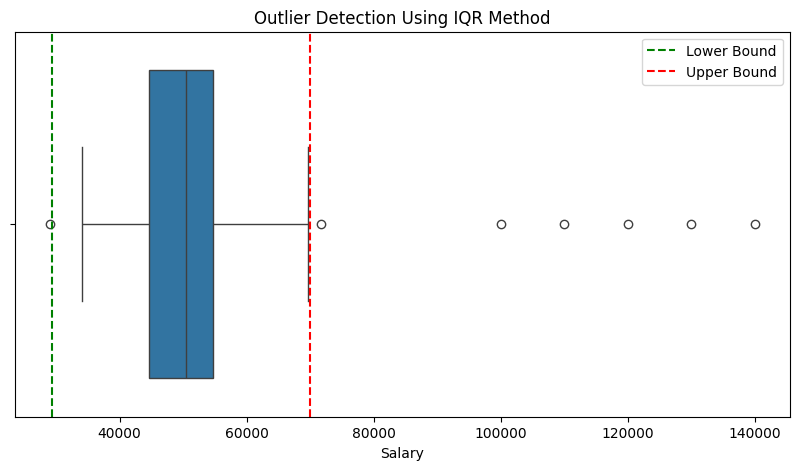

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Salary'])

plt.axvline(
    lower_bound,
    color='green',
    linestyle='--',
    label='Lower Bound'
)

plt.axvline(
    upper_bound,
    color='red',
    linestyle='--',
    label='Upper Bound'
)

plt.title("Outlier Detection Using IQR Method")
plt.legend()

plt.show()

In [ ]:
# Calculate Z-scores
df['Z_Score'] = stats.zscore(df['Salary'])

# Identify outliers
zscore_outliers = df[
    abs(df['Z_Score']) > 3
]

print("Z-Score Method Results")
print("----------------------")

print("Mean:", df['Salary'].mean())
print("Standard Deviation:", df['Salary'].std())

print("\nNumber of Outliers:", len(zscore_outliers))

print("\nOutlier Values:")
display(zscore_outliers)

Z-Score Method Results
----------------------
Mean: 51389.104662071535
Standard Deviation: 13314.607120979239

Number of Outliers: 5

Outlier Values:


,Salary,Z_Score
200,100000.0,3.659882
201,110000.0,4.412776
202,120000.0,5.165669
203,130000.0,5.918562
204,140000.0,6.671456


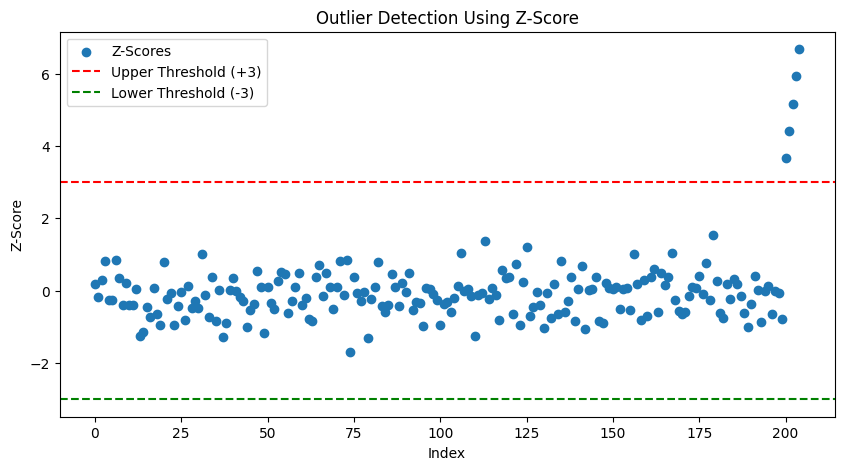

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df.index,
    df['Z_Score'],
    label='Z-Scores'
)

plt.axhline(
    3,
    color='red',
    linestyle='--',
    label='Upper Threshold (+3)'
)

plt.axhline(
    -3,
    color='green',
    linestyle='--',
    label='Lower Threshold (-3)'
)

plt.title("Outlier Detection Using Z-Score")
plt.xlabel("Index")
plt.ylabel("Z-Score")

plt.legend()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Method': ['IQR Method', 'Z-Score Method'],
    'Number of Outliers': [
        len(iqr_outliers),
        len(zscore_outliers)
    ]
})

print("Comparison of Outlier Detection Methods:")
display(comparison)

Comparison of Outlier Detection Methods:


,Method,Number of Outliers
0,IQR Method,7
1,Z-Score Method,5


In [ ]:
# Remove outliers using IQR bounds
df_removed = df[
    (df['Salary'] >= lower_bound) &
    (df['Salary'] <= upper_bound)
].copy()

print("Original Dataset Size:", len(df))
print("Dataset Size After Removing Outliers:", len(df_removed))

print("\nDataset After Outlier Removal:")
display(df_removed.head())

Original Dataset Size: 205
Dataset Size After Removing Outliers: 198

Dataset After Outlier Removal:


,Salary,Z_Score
0,53973.713224,0.194593
1,48893.885591,-0.187863
2,55181.508305,0.285528
3,62184.238851,0.812759
4,48126.773002,-0.245619


In [ ]:
# Create a copy of original dataset
df_capped = df.copy()

# Apply capping
df_capped['Salary'] = df_capped['Salary'].clip(
    lower=lower_bound,
    upper=upper_bound
)

print("Original Salary Values:")
display(df[['Salary']].tail(5))

print("\nSalary Values After Capping:")
display(df_capped[['Salary']].tail(5))

Original Salary Values:


,Salary
200,100000.0
201,110000.0
202,120000.0
203,130000.0
204,140000.0



Salary Values After Capping:


,Salary
200,69897.438535
201,69897.438535
202,69897.438535
203,69897.438535
204,69897.438535


In [ ]:
# Remove rows having absolute Z-score greater than 3
df_zscore_removed = df[
    abs(df['Z_Score']) <= 3
].copy()

print("Original Dataset Size:", len(df))
print("Dataset Size After Z-score Treatment:", len(df_zscore_removed))

display(df_zscore_removed.head())

Original Dataset Size: 205
Dataset Size After Z-score Treatment: 200


,Salary,Z_Score
0,53973.713224,0.194593
1,48893.885591,-0.187863
2,55181.508305,0.285528
3,62184.238851,0.812759
4,48126.773002,-0.245619


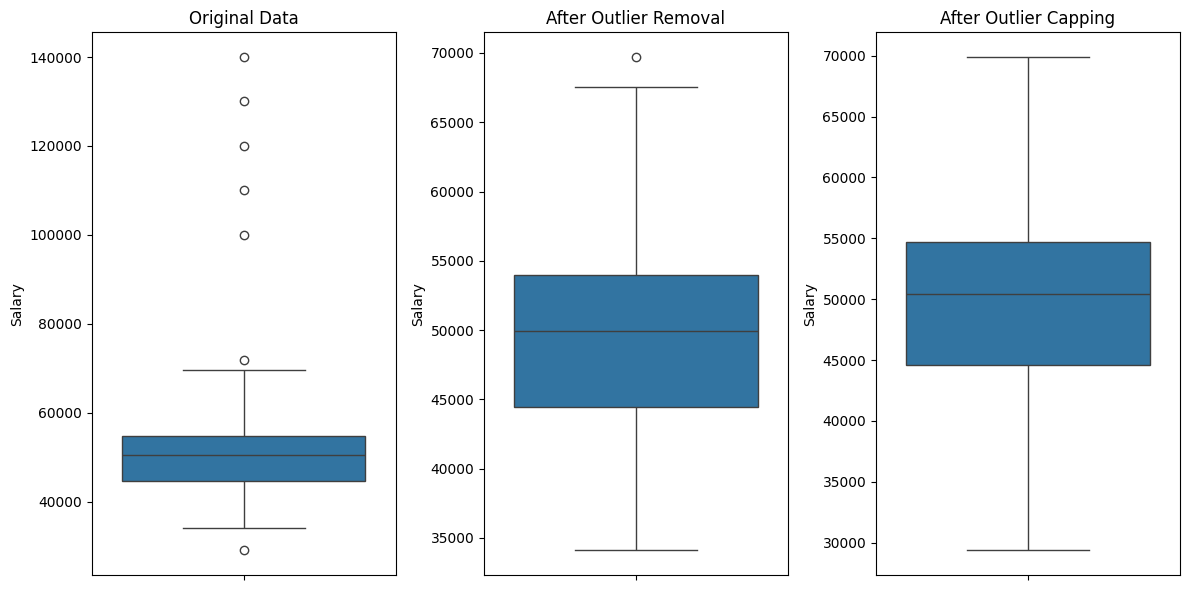

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['Salary'])
plt.title("Original Data")

plt.subplot(1, 3, 2)
sns.boxplot(y=df_removed['Salary'])
plt.title("After Outlier Removal")

plt.subplot(1, 3, 3)
sns.boxplot(y=df_capped['Salary'])
plt.title("After Outlier Capping")

plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    'Dataset': [
        'Original Data',
        'After IQR Removal',
        'After IQR Capping',
        'After Z-score Removal'
    ],

    'Count': [
        len(df),
        len(df_removed),
        len(df_capped),
        len(df_zscore_removed)
    ],

    'Mean Salary': [
        df['Salary'].mean(),
        df_removed['Salary'].mean(),
        df_capped['Salary'].mean(),
        df_zscore_removed['Salary'].mean()
    ],

    'Standard Deviation': [
        df['Salary'].std(),
        df_removed['Salary'].std(),
        df_capped['Salary'].std(),
        df_zscore_removed['Salary'].std()
    ]
})

display(results.round(2))

,Dataset,Count,Mean Salary,Standard Deviation
0,Original Data,205,51389.10,13314.61
1,After IQR Removal,198,49666.48,7169.32
2,After IQR Capping,205,50159.54,7965.61
3,After Z-score Removal,200,49673.83,7448.03


In [ ]:
print("FINAL RESULT")
print("============")

print("Total observations:", len(df))

print("\nIQR Method:")
print("Outliers detected:", len(iqr_outliers))
print("Remaining observations:", len(df_removed))

print("\nZ-Score Method:")
print("Outliers detected:", len(zscore_outliers))
print("Remaining observations:", len(df_zscore_removed))

print("\nOutlier treatment completed successfully!")

FINAL RESULT
Total observations: 205

IQR Method:
Outliers detected: 7
Remaining observations: 198

Z-Score Method:
Outliers detected: 5
Remaining observations: 200

Outlier treatment completed successfully!
